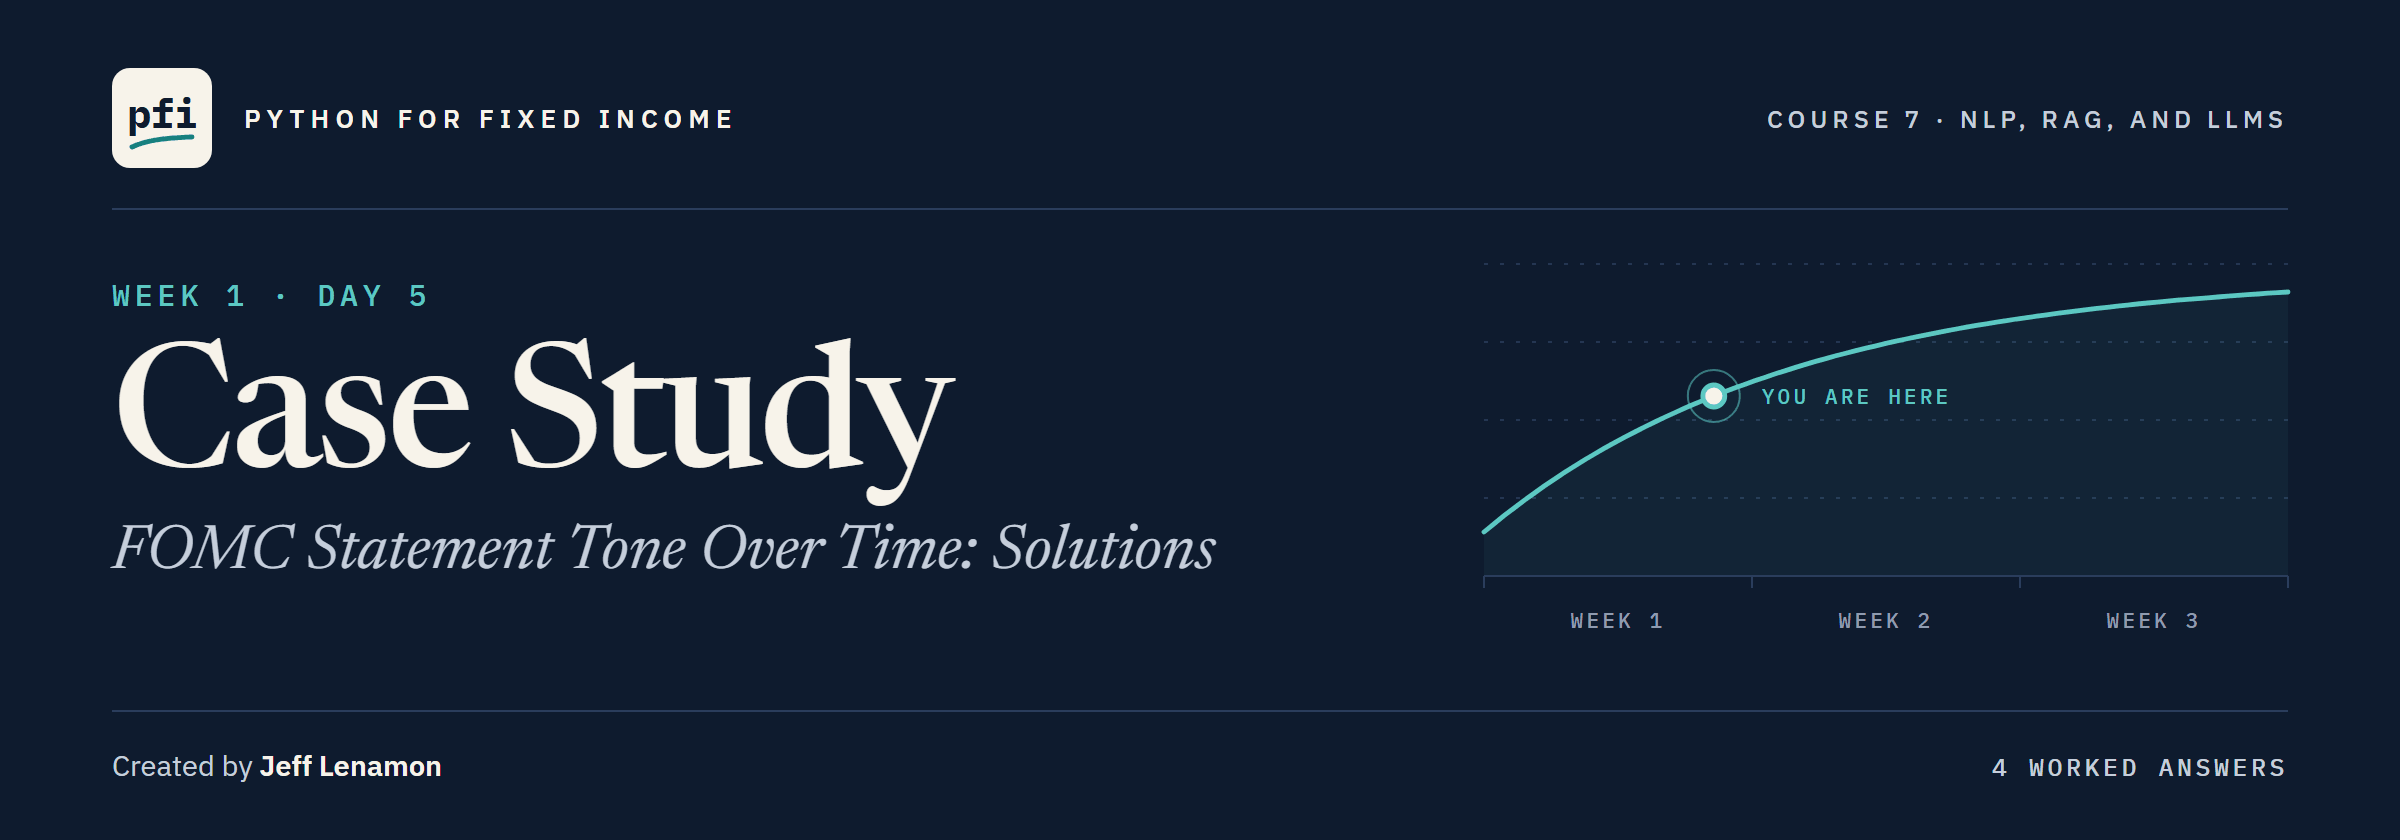

# Case Study: FOMC Statement Tone Over Time: Solutions

Week 1, Day 5. The full notebook with every exercise worked. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day5/05_case_study_fomc_statement_tone_over_time_solutions.ipynb)

# Problem Statement

## Business Context

A colleague asks two things of the 213 statements published after scheduled FOMC meetings from 2000 to 2026.
How did a count of the course's firming and easing words move by date?
And do the words of a statement, outside the sentence that states its action, sit beside a stated raise?
In this notebook "tone" means that count from the course's two lists, and nothing more.
The statements are real public documents, described only: no number here says what the Committee meant or will do, and no score is lined up against market moves.
Every score from a fitted model is walk-forward: each year's statements are scored by a model fitted only on earlier years, from 2005.

## Objectives

Write two word lists and score a text per thousand tokens.
Read the action a statement states with a rule, and check it against the rate it states.
Take the label's own sentence out of the text before any score.
Score dated statements walk-forward by calendar year.
Read what a fitted model leans on, and test a suspected leak.
Put a word count and a classifier's score side by side by date, and say where each fails.

## Data Dictionary

`course7_fomc_statements.csv`, one row per statement (Day 1):

1. `date`: the meeting's date, as text
2. `url`: the statement's page on federalreserve.gov
3. `scheduled`: True after a scheduled meeting, False after an unscheduled one
4. `text`: the statement as published, one paragraph per line

Made in the notebook: `policy` (Day 2's policy text), `action` (raise, lower, hold or none), `label` (raise or other), `kept` (the policy text without the sentences that name the federal funds rate or a target range), `dictionary` (the word-list score), and for each scored statement `score` and `assigned`.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text: regular expressions, Unicode forms, and textwrap to cut a long sentence into lines
import re
import textwrap
import unicodedata

# data, charts and a dropdown; Path from matplotlib draws a curve, so it is named CurvePath here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.path import Path as CurvePath
from matplotlib.patches import PathPatch
from ipywidgets import interact

# scikit-learn: the vectorizer, the classifier, the pipeline and the scores
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, recall_score, confusion_matrix

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

# one colour for each of the four kinds of row a confusion matrix counts
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

## Day 1's and Day 2's Pieces in One Cell

Day 1 and Day 2 wrote these lines; they are repeated here as one cell, unchanged.
Every excerpt prints through `normalize_text` with its source line.

In [3]:
# Day 1's map of look-alike characters, normalize_text, the token and tokenize
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}


def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"


def tokenize(text):
    """The course's tokens of a text, in lower case, after normalize_text."""
    return re.findall(TOKEN_PATTERN, normalize_text(text).lower())


# Day 2's policy text: a paragraph that names members says voting, or names a Governor or a President
VOTE = re.compile(r"Voting|voting|Governor [A-Z]|President [A-Z]")


def policy_text(text):
    """A statement after normalize_text, without the paragraphs that name members."""
    return "\n".join(paragraph for paragraph in normalize_text(text).split("\n") if not VOTE.search(paragraph))


# Day 1's source line
def statement_source(row):
    """Print the source line of one statement."""
    print(f"Source: FOMC post-meeting statement of {row['date']}, Board of Governors of the Federal Reserve System, {row['url']}")

## Day 1's Stated Rate in One Cell

In [4]:
# Day 1's four wordings of a stated rate, tried in this order, and the written rate as a number of percent
NUMBER = r"(?:\d+[- ]\d+/\d+|\d+/\d+|\d+)"
RANGE = (rf"target range for the federal funds rate(?: by {NUMBER} percentage point,?)?"
         rf" (?:at|to|of) (?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent")
CURRENT = rf"(?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent target range"
DIRECTIVE = rf"federal funds rate in a target range of (?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent"
TARGET = rf"target for the federal funds rate[^.]*? (?:to|at) (?P<target>{NUMBER}) percent"
WORDINGS = {"range": RANGE, "current": CURRENT, "directive": DIRECTIVE, "target": TARGET}


def stated_rate(text):
    """The kind of rate a statement states, with its low and high ends as written."""
    for kind, pattern in WORDINGS.items():
        found = re.search(pattern, text)
        if found and kind == "target":
            return kind, found["target"], found["target"]
        if found:
            return kind, found["low"], found["high"]
    return "none", None, None


def written_to_number(written):
    """A rate as the statements write it ("5-3/4", "1 3/4", "1/4", "4") as a number of percent."""
    number = 0.0
    for part in written.replace(" ", "-").split("-"):
        if "/" in part:
            top, bottom = part.split("/")
            number += int(top) / int(bottom)
        else:
            number += int(part)
    return number

# Loading the Data

## The Statements

In [5]:
# every statement, its year, and Day 2's policy text
statements = pd.read_csv(DATA + "course7_fomc_statements.csv")
statements["year"] = statements["date"].str[:4].astype(int)
statements["policy"] = statements["text"].map(policy_text)
print(statements.shape, "|", statements["scheduled"].value_counts().to_dict())

(226, 6) | {True: 213, False: 13}


213 statements follow scheduled meetings and 13 unscheduled ones (Day 1).

The policy text leaves out the vote paragraphs (Day 2), where a dissent states a preferred action.

# Data Overview

## Sentences

The day reads statements sentence by sentence.
`re.split(pattern, text)` cuts a text at every match of the pattern.
`(?<=[.!?])` is a **look-behind**: it matches the place just after a full stop, question mark or exclamation mark, without taking the mark (Day 1's Exercise 2 used it).

In [6]:
# a sentence ends where a full stop, question mark or exclamation mark is followed by white space
def sentences(text):
    """The sentences of a text, after normalize_text."""
    return re.split(r"(?<=[.!?])\s+", normalize_text(text))


# a typed example: "2.5" stays whole, since its full stop is followed by a digit
print(sentences("The rate rose to 5-1/4 percent. Inflation was 2.5 percent."))

['The rate rose to 5-1/4 percent.', 'Inflation was 2.5 percent.']


## The Rows of the Case Study

In [7]:
# the 213 scheduled statements: sentences in all, and the fewest, median and most in one statement
scheduled = statements[statements["scheduled"]].reset_index(drop=True)
per_statement = scheduled["policy"].map(sentences).str.len()
print(len(scheduled), "statements |", per_statement.sum(), "sentences |", per_statement.min(), per_statement.median(), per_statement.max())

213 statements | 2899 sentences | 4 13.0 26


The 13 unscheduled statements are releases between meetings, and stay out of every count and model.

**Every count and model today reads the policy text of the 213 scheduled statements; the rate check alone reads all 226.**

# The Course's Word Lists

## Two Lists, Printed Whole

Course 1's Case Study: Statement Sentiment notebook scored its own two word lists per 100 tokens and tried VADER.
This course writes its own two lists, printed whole: a choice, one of many.

In [8]:
# the course's firming words and easing words
FIRMING = ["raise", "increase", "tighten", "firming", "elevated"]
EASING = ["lower", "reduce", "accommodation", "accommodative", "easing"]
print("firming:", FIRMING)
print("easing: ", EASING)

firming: ['raise', 'increase', 'tighten', 'firming', 'elevated']
easing:  ['lower', 'reduce', 'accommodation', 'accommodative', 'easing']


## `dictionary_score`

A **dictionary score** counts a text's firming tokens less its easing tokens, per thousand tokens, so a long statement scores no higher for its length.

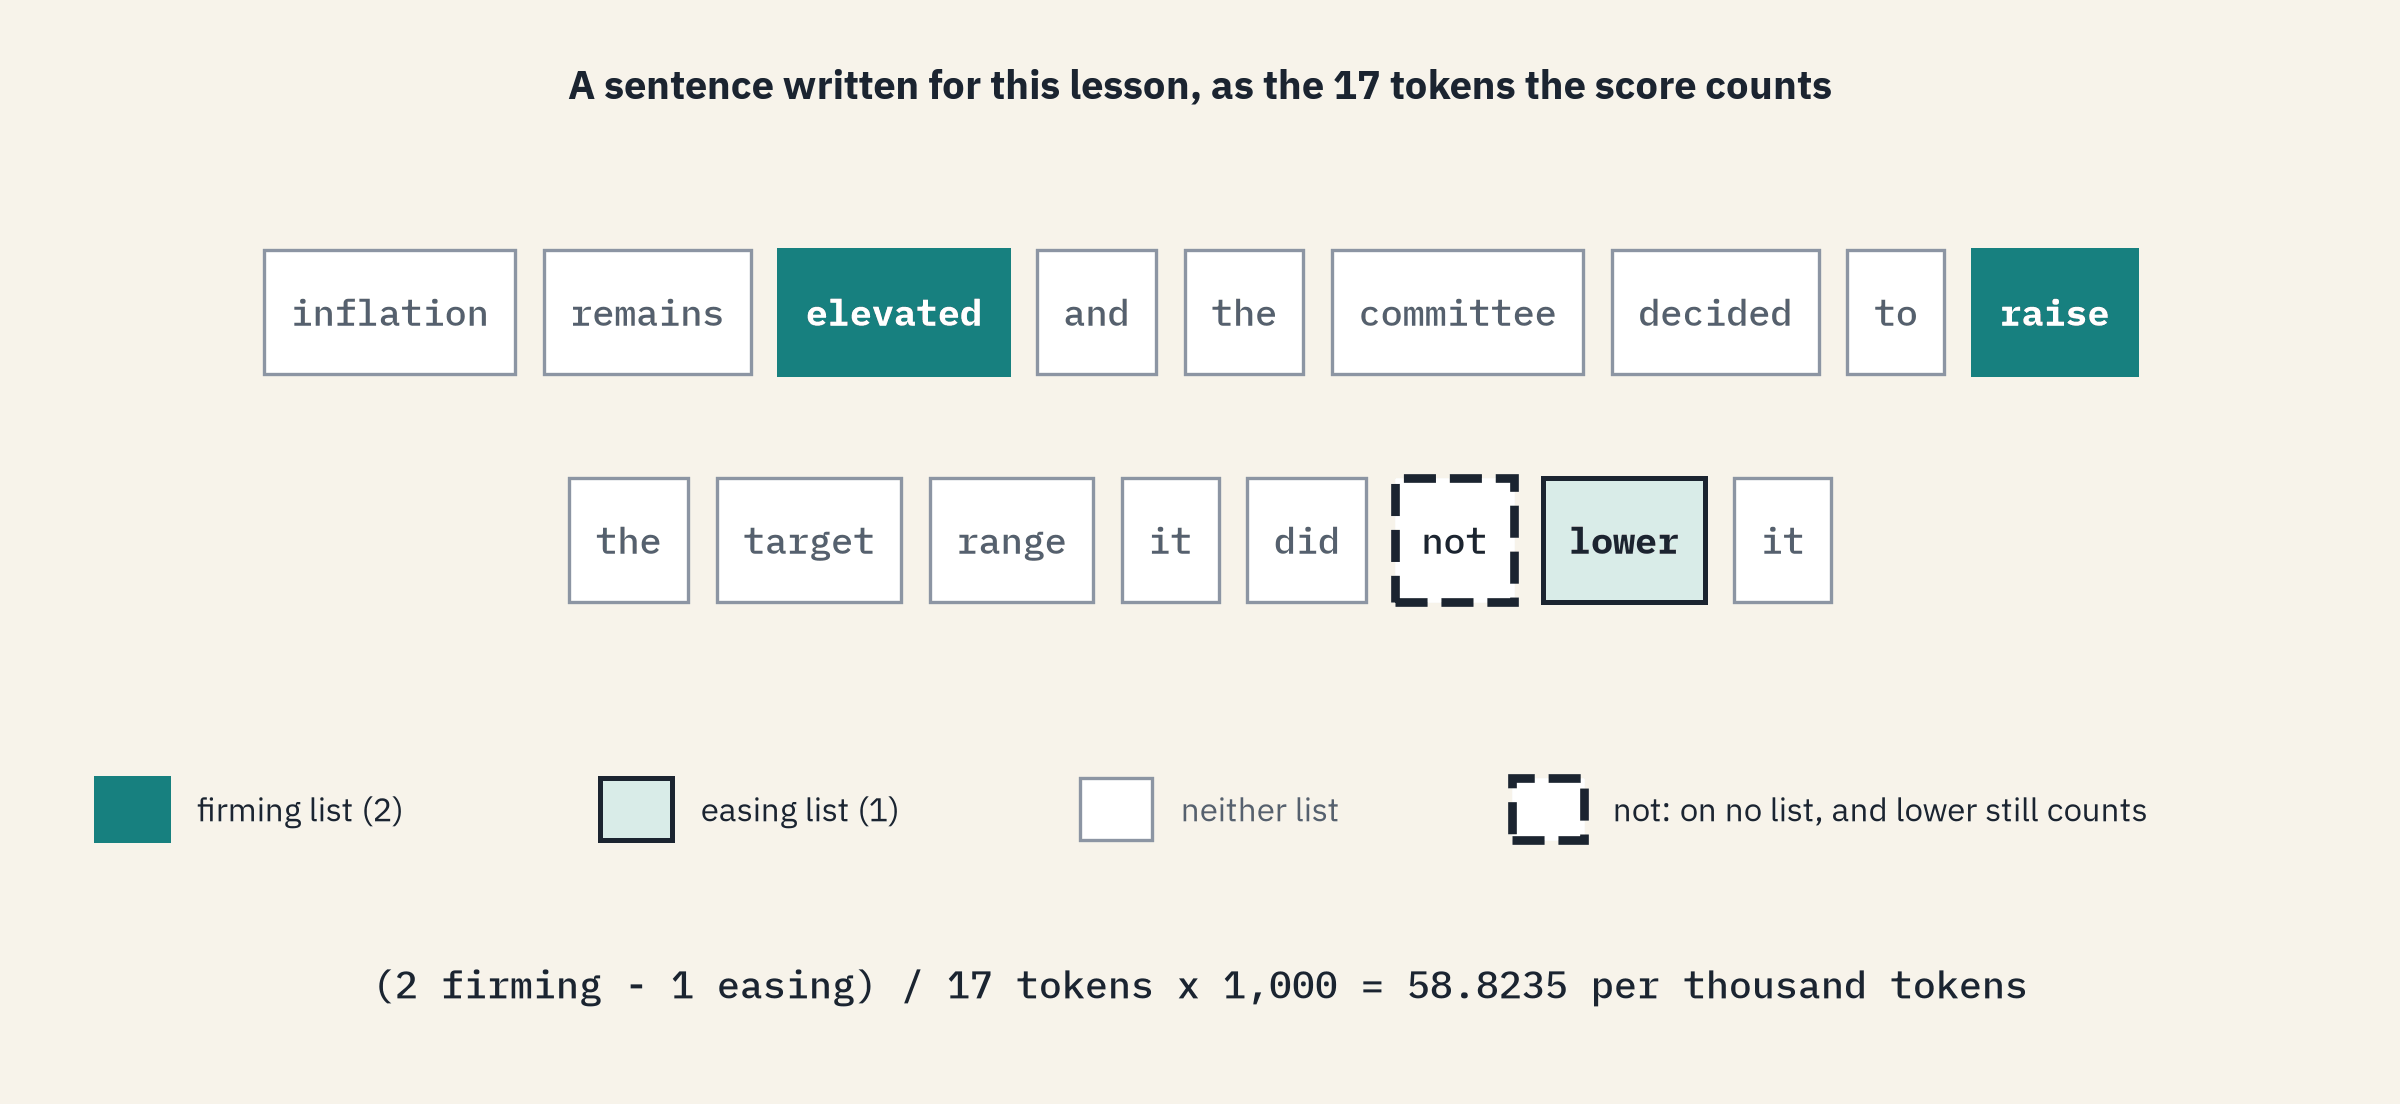

The sentence above was written for this lesson, from no statement.

In [9]:
# firming tokens less easing tokens, per thousand tokens
def dictionary_score(text, firming, easing):
    """Firming tokens less easing tokens, per thousand tokens of the text."""
    tokens = tokenize(text)
    return (sum(token in firming for token in tokens) - sum(token in easing for token in tokens)) / len(tokens) * 1000


hand = "Inflation remains elevated, and the Committee decided to raise the target range; it did not lower it."
print(len(tokenize(hand)), "tokens |", round(dictionary_score(hand, FIRMING, EASING), 4))

17 tokens | 58.8235


2 firming tokens less 1 easing token, over 17 tokens, times 1,000: 58.8235.

"did not lower" still counts "lower" as easing: a list counts words, never what a sentence says about them.

## How Often Each Word Appears

In [10]:
# every scheduled policy text as tokens, then each listed word's count in all 213
scheduled["tokens"] = scheduled["policy"].map(tokenize)
counts = pd.Series({word: sum(tokens.count(word) for tokens in scheduled["tokens"]) for word in FIRMING + EASING})
print(counts.sort_values(ascending=False, kind="stable").to_dict())

{'accommodative': 156, 'elevated': 103, 'accommodation': 77, 'lower': 64, 'increase': 59, 'raise': 49, 'firming': 25, 'reduce': 21, 'easing': 15, 'tighten': 0}


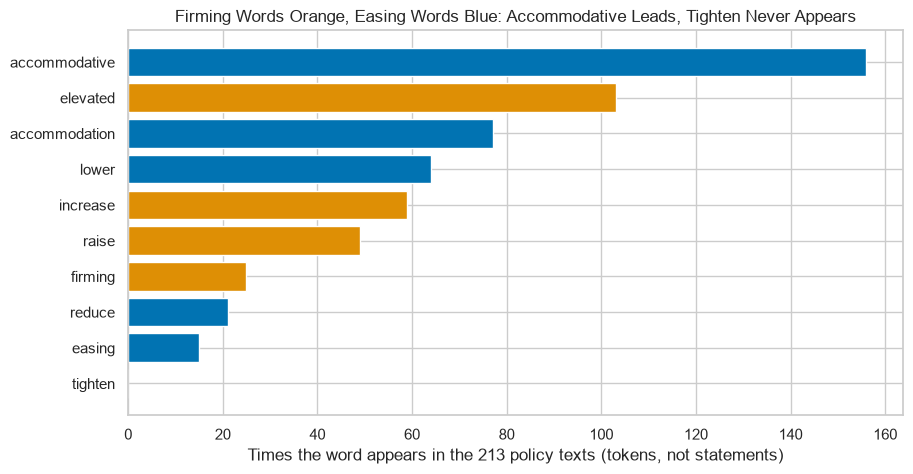

In [11]:
# the ten words by count, firming words in orange and easing words in blue
counts = counts.sort_values(kind="stable")
plt.barh(counts.index, counts, color=["C1" if word in FIRMING else "C0" for word in counts.index])
plt.xlabel("Times the word appears in the 213 policy texts (tokens, not statements)")
plt.title("Firming Words Orange, Easing Words Blue: Accommodative Leads, Tighten Never Appears")
plt.show()

"tighten" is in no statement, so one firming word counts nothing.

"raise" appears 49 times: a count of the word, not of statements.

**The lists count words, never what the words are about.**

# The Action Each Statement States

**Predict 1**

Day 1 drew the rate each statement states.

Q. Of the 213 scheduled statements, how many state a raise of the target, how many a lower target, and how many keep it? Write down three numbers.

## Where a Statement States Its Action

Each statement states its action in one sentence that names the federal funds rate and its target.
Six verbs state it: raise, then lower and establish (a new range below the last rate), then keep, maintain and reaffirmed.

In [12]:
# the six verbs, and the action each one states
VERBS = {"raise": "raise", "lower": "lower", "establish": "lower", "keep": "hold", "maintain": "hold", "reaffirmed": "hold"}


def action_sentence(text):
    """The first sentence that names the federal funds rate and its target and holds one of the six verbs."""
    for sentence in sentences(text):
        if "federal funds" in sentence and "target" in sentence and any(token in VERBS for token in tokenize(sentence)):
            return sentence
    return None

In [13]:
# source text: quoted as published
# the first statement's action sentence
print(action_sentence(scheduled["policy"][0]))
statement_source(scheduled.iloc[0])

The Federal Open Market Committee voted today to raise its target for the federal funds rate by 25 basis points to 5-3/4 percent.
Source: FOMC post-meeting statement of 2000-02-02, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/boarddocs/press/general/2000/20000202/


A **word tree** puts the six verbs in one column, the two words before each branching to the left and the two after branching to the right, each line as wide as its count of statements.

In [14]:
# source text: quoted as published
# every action sentence as tokens, cut to the two before the verb, the verb, and the two after it
paths = []
for sentence in scheduled["policy"].map(action_sentence):
    tokens = tokenize(sentence)
    at = [token in VERBS for token in tokens].index(True)
    paths.append(tokens[at - 2:at + 3])
paths = pd.DataFrame(paths, columns=["left2", "left1", "verb", "right1", "right2"])
print(paths.value_counts(["left2", "left1"]).to_dict())
print(paths.value_counts(["right1", "right2"]).to_dict())

{('decided', 'to'): 108, ('today', 'to'): 71, ('committee', 'will'): 18, ('committee', 'today'): 9, ('long', 'to'): 5, ('committee', 'also'): 2}
{('the', 'target'): 124, ('its', 'target'): 67, ('its', 'view'): 9, ('the', 'existing'): 5, ('the', 'current'): 5, ('its', 'expectation'): 2, ('a', 'target'): 1}


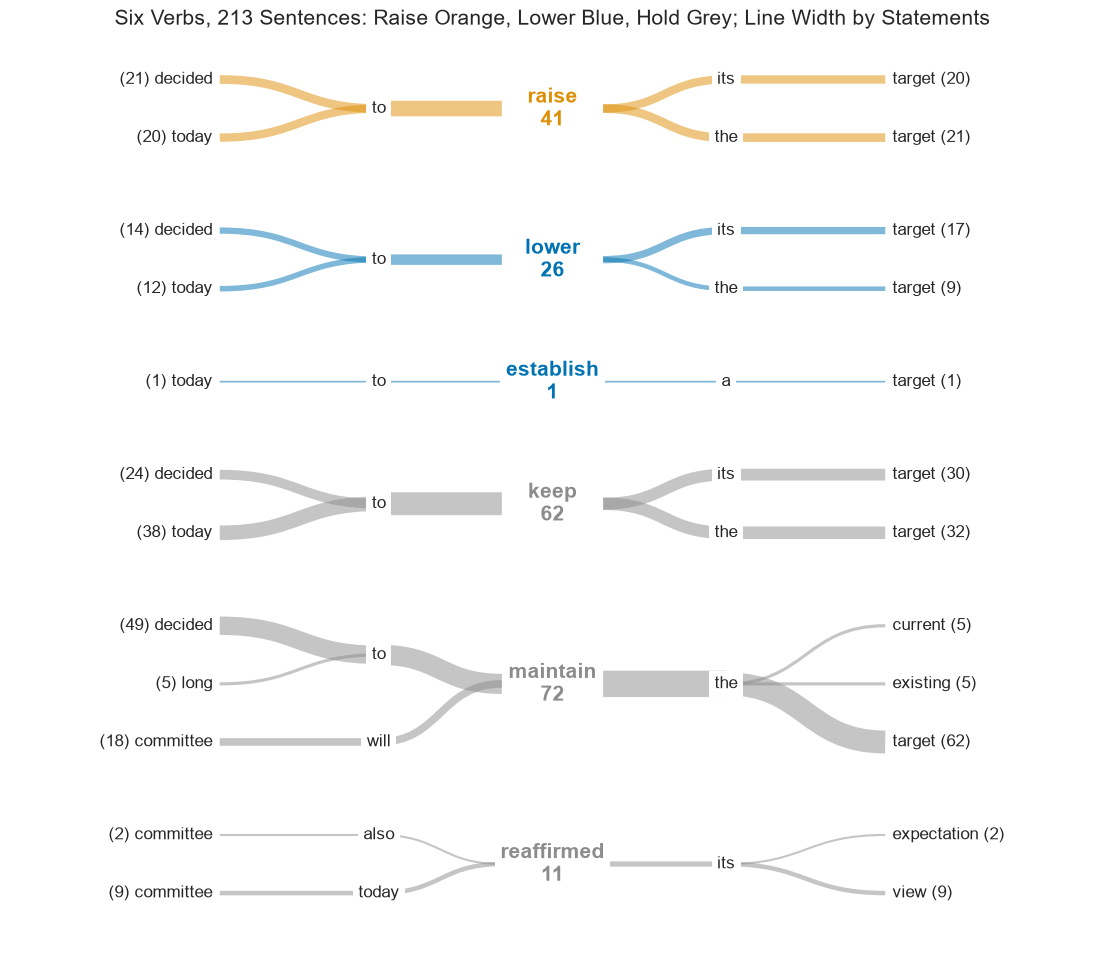

In [15]:
# the word tree: verbs in the middle, the words before them to the left, the words after to the right
ACTION_COLOURS = {"raise": "C1", "lower": "C0", "hold": "0.55"}
fig, ax = plt.subplots(figsize=(14, 12))


def branch(x0, y0, x1, y1, count, colour):
    """One branch as wide as its count of statements (CURVE4 bends a CurvePath through two control points)."""
    middle = (x0 + x1) / 2
    curve = CurvePath([(x0, y0), (middle, y0), (middle, y1), (x1, y1)], [CurvePath.MOVETO] + [CurvePath.CURVE4] * 3)
    ax.add_patch(PathPatch(curve, facecolor="none", edgecolor=colour, lw=1 + count / 4, alpha=0.5))


top = 0
for verb in VERBS:
    group, colour = paths[paths["verb"] == verb], ACTION_COLOURS[VERBS[verb]]
    # side -1 is the left, 1 the right: each side's word pairs and their counts, sorted by the word next to the verb
    sides = {-1: group.value_counts(["left1", "left2"]).sort_index(), 1: group.value_counts(["right1", "right2"]).sort_index()}
    rows = max(len(pairs) for pairs in sides.values())
    centre = top - (rows - 1) / 2
    ax.text(0, centre, f"{verb}\n{len(group)}", ha="center", va="center", fontsize=15, weight="bold", color=colour,
            bbox={"facecolor": "white", "edgecolor": "none"})
    for side, pairs in sides.items():
        ys = centre + (len(pairs) - 1) / 2 - np.arange(len(pairs))
        nexts = pairs.index.get_level_values(0)  # the word next to the verb in each pair
        for word in nexts.unique():
            mid = ys[nexts == word].mean()
            branch(0.7 * side, centre, 2.4 * side, mid, pairs[word].sum(), colour)
            ax.text(2.4 * side, mid, word, ha="center", va="center", fontsize=12, bbox={"facecolor": "white", "edgecolor": "none"})
            for y, (outer, n) in zip(ys[nexts == word], pairs[word].items()):
                branch(2.4 * side, mid, 4.6 * side, y, n, colour)
                ax.text(4.7 * side, y, f"{outer} ({n})" if side > 0 else f"({n}) {outer}", ha="left" if side > 0 else "right", va="center", fontsize=12)
    top = centre - (rows + 1) / 2 - 0.6
ax.set(xlim=(-7.5, 7.5), ylim=(top + 0.5, 0.8))
ax.set_axis_off()
ax.set_title("Six Verbs, 213 Sentences: Raise Orange, Lower Blue, Hold Grey; Line Width by Statements", fontsize=15)
plt.show()

Most sentences read "decided to" or "today to" before the verb, and "the target" or "its target" after it.

"reaffirmed its view" and "maintain the existing" or "the current" reach the target later in the sentence.

## `policy_action`

In [16]:
# the action of the first of the six verbs in a statement's action sentence, or none
def policy_action(text):
    """The action a statement states: the first of the six verbs in its action sentence, else none."""
    sentence = action_sentence(text)
    if sentence is None:
        return "none"
    return VERBS[[token for token in tokenize(sentence) if token in VERBS][0]]


# every statement's action, then the scheduled rows again with it
statements["action"] = statements["policy"].map(policy_action)
print(pd.crosstab(statements["scheduled"], statements["action"]).to_string())
scheduled = statements[statements["scheduled"]].reset_index(drop=True)

action     hold  lower  none  raise
scheduled                          
False         2      7     4      0
True        145     27     0     41


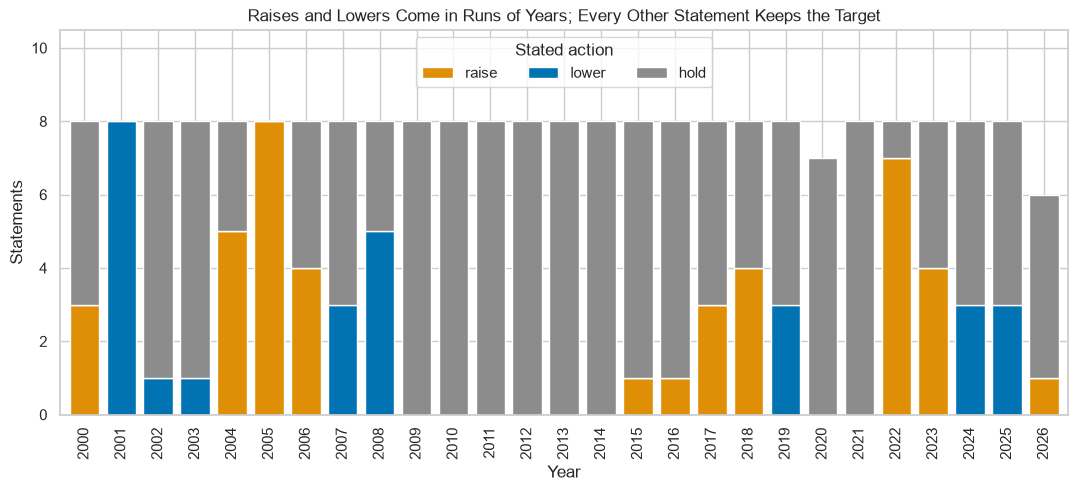

In [17]:
# scheduled statements by year and the action each states, stacked
by_year = pd.crosstab(scheduled["year"], scheduled["action"])[["raise", "lower", "hold"]]
by_year.plot.bar(stacked=True, color=[ACTION_COLOURS[action] for action in by_year.columns], width=0.8, figsize=(13, 5))
plt.xlabel("Year")
plt.ylabel("Statements")
plt.legend(title="Stated action", ncol=3, loc="upper center")
plt.ylim(0, 10.5)
plt.title("Raises and Lowers Come in Runs of Years; Every Other Statement Keeps the Target")
plt.show()

Every scheduled statement states an action: 41 raises, 27 lowers and 145 holds.

Raises come in 2000, 2004 to 2006, 2015 to 2018, 2022 to 2023 and 2026; every statement of 2009 to 2014 holds.

## Checked Against the Rate Each Statement States

Day 1's stated rate gives each statement a number: the middle of its range, or its single target.
Course 5B's `.ffill()` and `.shift()` give the last rate stated before it, and `np.sign` turns a move into 1, -1 or 0.

In [18]:
# every statement's stated rate, its middle in percent, and its move from the last rate stated before it (all 226)
rates = pd.DataFrame(statements["text"].map(normalize_text).map(stated_rate).tolist(), columns=["kind", "low", "high"])
middle = (rates["low"].map(written_to_number, na_action="ignore") + rates["high"].map(written_to_number, na_action="ignore")) / 2
statements["move"] = middle - middle.ffill().shift()

# a raise should move up, a lower down, a hold not at all
expected = statements["action"].map({"raise": 1, "lower": -1, "hold": 0})
checkable = expected.notna() & statements["move"].notna()
print(checkable.sum(), "checkable |", (np.sign(statements["move"][checkable]) == expected[checkable]).sum(), "agree")

221 checkable | 221 agree


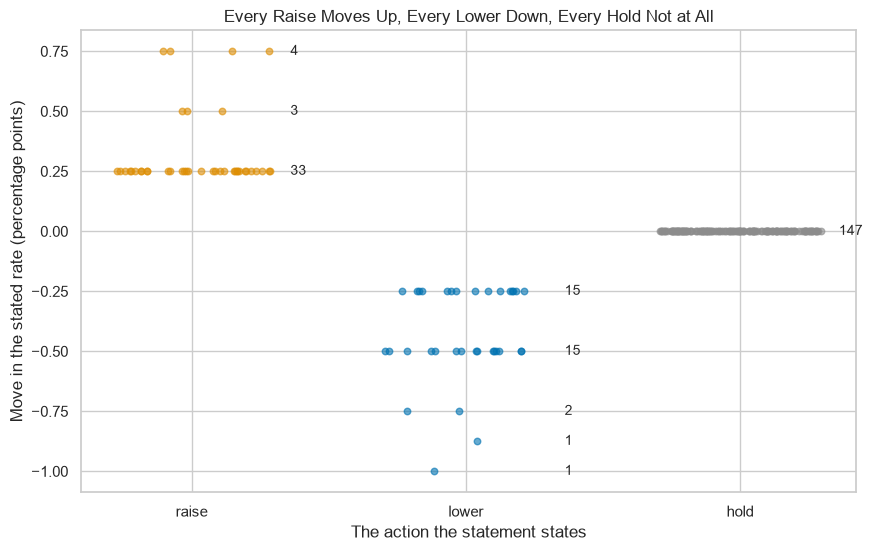

In [19]:
# each move by its action, a dot per statement, spread sideways by a seeded generator so the dots do not hide each other
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(10, 6))
for k, action in enumerate(["raise", "lower", "hold"]):
    moves = statements.loc[checkable & (statements["action"] == action), "move"]
    ax.scatter(k + rng.uniform(-0.3, 0.3, len(moves)), moves, s=22, alpha=0.6, color=ACTION_COLOURS[action])
    for move, n in moves.value_counts().items():
        ax.text(k + 0.36, move, n, va="center", fontsize=10)
ax.set(xticks=[0, 1, 2], xticklabels=["raise", "lower", "hold"], xlabel="The action the statement states",
       ylabel="Move in the stated rate (percentage points)", title="Every Raise Moves Up, Every Lower Down, Every Hold Not at All")
plt.show()

All 221 statements with an action and a rate stated before them agree.

The lone -0.875 is 2008-12-16: a single target of 1 percent, then the range 0 to 1/4 percent, read at its middle (the course's choice of one number for a range).

An earlier version of this course read 2019-10-11 and 2020-03-23 as stating no action; their directive's "maintain" reads hold.

**A label read by a rule is a claim; the statement's own number checks it.**

# Data Preparation for Modeling

## The Label Is in the Text

Day 3 put each 8-K section's heading back and scored 0.9899: the label was in the text.
Here the label is a sentence of the statement itself, so that sentence must go before any model is fitted on the text.

In [20]:
# the label the classifier learns: raise, or other for every other statement
scheduled["label"] = np.where(scheduled["action"] == "raise", "raise", "other")
scheduled["tokens"] = scheduled["policy"].map(tokenize)
scored = scheduled[scheduled["year"] >= 2005]
print(len(scored), "statements from 2005 |", scored["label"].value_counts().to_dict())

173 statements from 2005 | {'other': 140, 'raise': 33}


## One Word as a Rule

A rule with no model: assign raise wherever the policy text holds the token "raise".
Day 3's macro F1 scores it, against the majority label, other, assigned to every statement.

In [21]:
# the one-word rule and the majority label on the statements of 2005 to 2026
rule = np.where(["raise" in tokens for tokens in scored["tokens"]], "raise", "other")
majority = ["other"] * len(scored)
print(f"rule: macro F1 {f1_score(scored['label'], rule, average='macro'):.4f}")
print(f"majority: macro F1 {f1_score(scored['label'], majority, average='macro'):.4f} | accuracy {(scored['label'] == 'other').mean():.4f}")

rule: macro F1 0.9392
majority: macro F1 0.4473 | accuracy 0.8092


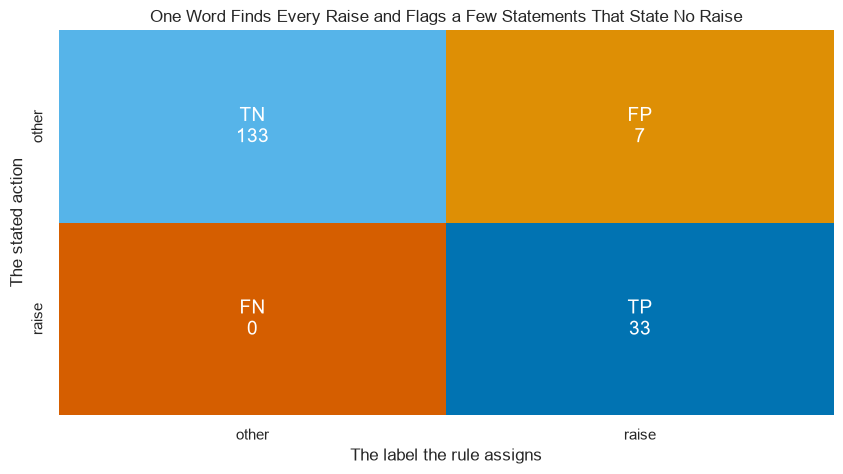

In [22]:
# the rule against the stated action, in Course 4's Day 7 colours
tn, fp, fn, tp = confusion_matrix(scored["label"], rule, labels=["other", "raise"]).ravel()
labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]
sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, annot_kws={"size": 14},
            xticklabels=["other", "raise"], yticklabels=["other", "raise"])
plt.xlabel("The label the rule assigns")
plt.ylabel("The stated action")
plt.title("One Word Finds Every Raise and Flags a Few Statements That State No Raise")
plt.show()

In [23]:
# source text: quoted as published
# the statements the rule flags that state no raise: their dates and actions, then the first one's sentence holding "raise"
flagged = scored[(rule == "raise") & (scored["label"] == "other")]
print(flagged[["date", "action"]].to_string(index=False))
print([s for s in sentences(flagged["policy"].iloc[0]) if "raise" in tokenize(s)][0])
statement_source(flagged.iloc[0])

      date action
2015-03-18   hold
2015-04-29   hold
2015-06-17   hold
2015-07-29   hold
2015-09-17   hold
2015-10-28   hold
2022-01-26   hold
The Committee anticipates that it will be appropriate to raise the target range for the federal funds rate when it has seen further improvement in the labor market and is reasonably confident that inflation will move back to its 2 percent objective over the medium term.
Source: FOMC post-meeting statement of 2015-03-18, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/newsevents/pressreleases/monetary20150318a.htm


The rule finds all 33 raises and flags 7 statements that hold: six of 2015 and 2022-01-26.

In each, "raise" sits in a sentence about a later meeting.

**One word nearly gives the label away, because the label is a sentence of the text.**

**Predict 2**

The **kept text** is the policy text with every sentence that names "federal funds" or "target range" removed.

Q. "raise" appears 49 times in the policy texts. How many times does it appear in the kept texts? Write down a number.

## Removing the Sentences That Name the Rate

In [24]:
# every sentence naming the federal funds rate or a target range goes; the rest join with single spaces
def kept_text(text):
    """The text without its sentences that name the federal funds rate or a target range."""
    return " ".join(s for s in sentences(text) if "federal funds" not in s and "target range" not in s)


scheduled["kept"] = scheduled["policy"].map(kept_text)
kept_tokens = scheduled["kept"].map(tokenize)
print("sentences dropped:", per_statement.sum() - scheduled["kept"].map(sentences).str.len().sum(),
      f"| tokens kept: {kept_tokens.str.len().sum() / scheduled['tokens'].str.len().sum():.4f}")
print("actions found in the kept text:", (scheduled["kept"].map(policy_action) != "none").sum())
print({word: sum(tokens.count(word) for tokens in kept_tokens) for word in ["raise", "increase", "lower"]})

sentences dropped: 404 | tokens kept: 0.7986
actions found in the kept text: 0
{'raise': 0, 'increase': 55, 'lower': 38}


404 of 2,899 sentences go, and 0.7986 of the tokens stay.

No kept text states an action, and "raise" is gone; "increase" and "lower" stay, 55 and 38 times.

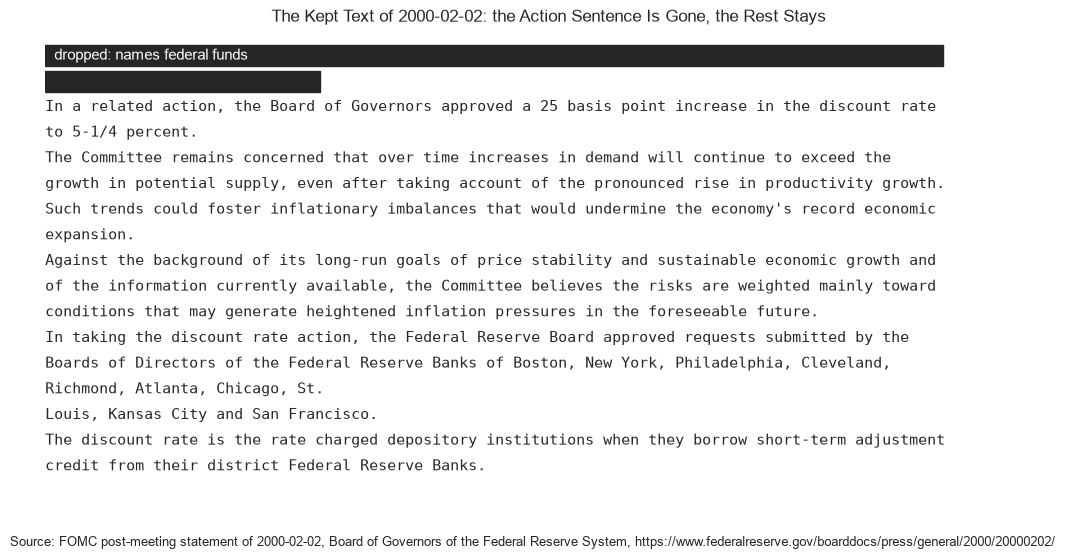

In [25]:
# source text: quoted as published
# 2000-02-02's policy text, a sentence a line: each sentence kept_text drops is covered by a bar naming what it matched
first_statement = scheduled.iloc[0]
fig, ax = plt.subplots(figsize=(13, 6))
line = 0
for sentence in sentences(first_statement["policy"]):
    matched = [phrase for phrase in ["federal funds", "target range"] if phrase in sentence]
    for k, piece in enumerate(textwrap.wrap(sentence, 100)):
        if matched:
            ax.add_patch(plt.Rectangle((0, -line - 0.4), len(piece), 0.8, color="0.15"))
            ax.text(1, -line, "dropped: names " + " and ".join(matched) if k == 0 else "", color="white", va="center", fontsize=11)
        else:
            ax.text(0, -line, piece, va="center", fontsize=11, family="monospace")
        line += 1
ax.set(xlim=(0, 110), ylim=(-line, 1))
ax.set_axis_off()
ax.set_title("The Kept Text of 2000-02-02: the Action Sentence Is Gone, the Rest Stays")
fig.text(0.5, 0.02, f"Source: FOMC post-meeting statement of {first_statement['date']}, Board of Governors of the Federal Reserve System, "
         f"{first_statement['url']}", ha="center", fontsize=9)
plt.show()

One sentence of eight goes, and the rest of the statement stays word for word.

The split also cuts after "St." in "St. Louis": a full stop is not always a sentence's end.

**Every score and model from here sees only the kept text, except the one run that shows the leak.**

# Model Building: Walk-Forward by Year

## Settings Fixed Before Scoring

The classifier is Day 3's: the course's TF-IDF and a logistic regression in one pipeline, with `C=1` and `class_weight="balanced"` written out.
Both were fixed before any statement was scored, and are never compared on the scored years.
With balanced weights the output is **the classifier's score for raise**, no longer a probability.

In [26]:
# the labels the first model fits on: the statements of 2000 to 2004
print(scheduled.loc[scheduled["year"] < 2005, "label"].value_counts().to_dict())

{'other': 32, 'raise': 8}


8 raises among 40 statements: the weights count each raise four times as much as each other statement.

## The Loop Written Out

Course 5B's Day 2 wrote the walk-forward loop; here each **fold** is one calendar year, scored by a model fitted on every earlier year.
Years hold 6 to 8 statements, so a fold is a year, not a count of rows.

In [27]:
# one fold per year from 2005: fit on the earlier years, score the year (column 1 of predict_proba is raise: labels sort, other first)
def walk_forward(text_column, label_column):
    """Each year from 2005 scored by a model fitted on the scheduled statements of earlier years only."""
    pieces = []
    for year in range(2005, 2027):
        train = scheduled[scheduled["year"] < year]
        test = scheduled[scheduled["year"] == year]
        model = make_pipeline(TfidfVectorizer(token_pattern=TOKEN_PATTERN, sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
                              LogisticRegression(C=1, max_iter=2000, class_weight="balanced"))
        model.fit(train[text_column], train[label_column])
        pieces.append(pd.DataFrame({"date": test["date"], "year": year, "label": test[label_column],
                                    "score": model.predict_proba(test[text_column])[:, 1], "assigned": model.predict(test[text_column])}))
    return pd.concat(pieces, ignore_index=True), model

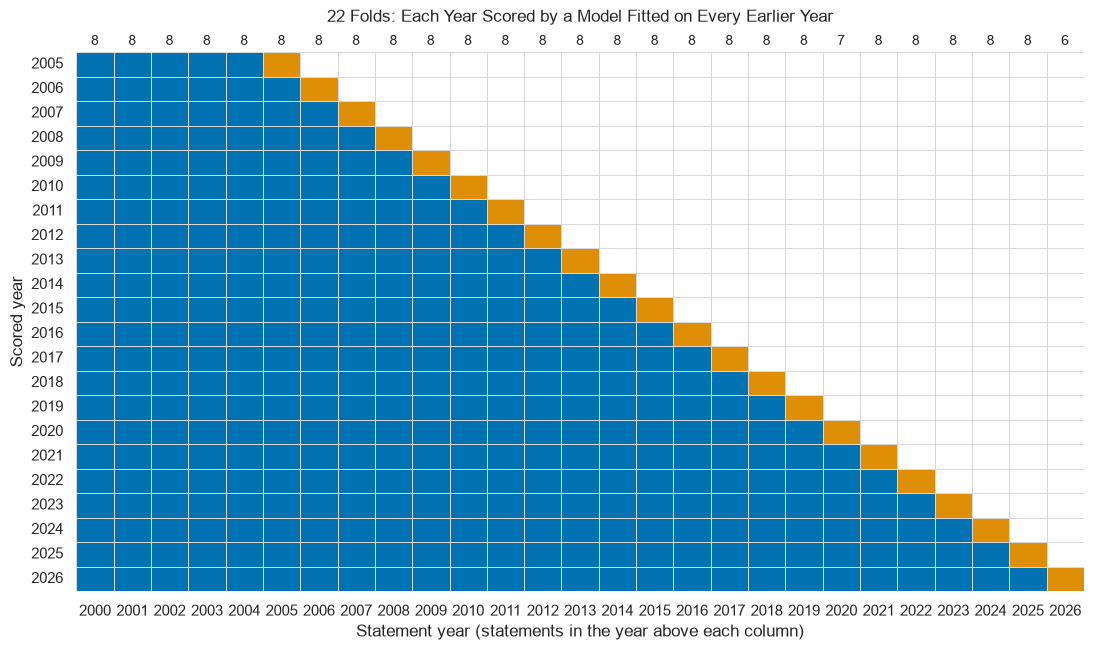

In [28]:
# the 22 folds: a row per scored year, training years blue and the scored year orange, statements per year on top
per_year = scheduled["year"].value_counts().sort_index()
grid = [[1 if year < scored_year else 2 if year == scored_year else 0 for year in per_year.index] for scored_year in range(2005, 2027)]
fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(grid, cmap=["white", "C0", "C1"], cbar=False, linewidths=0.5, linecolor="0.85", xticklabels=per_year.index, yticklabels=range(2005, 2027), ax=ax)
for k, n in enumerate(per_year):
    ax.text(k + 0.5, -0.3, n, ha="center", fontsize=10)
ax.set(xlabel="Statement year (statements in the year above each column)", ylabel="Scored year")
ax.set_title("22 Folds: Each Year Scored by a Model Fitted on Every Earlier Year", pad=22)
plt.show()

The first fold fits 40 statements of 2000 to 2004 and scores 2005's 8; the last fits 207 and scores 2026's 6.

173 statements are scored, once each.

**Predict 3**

The one word scored 0.9392 macro F1 and the majority label 0.4473.

Q. The classifier, walk-forward on the policy text with the action sentence still in: what macro F1 on the 173 statements? Write down a number.

## The Policy Text, Action Sentence In

In [29]:
# the leak left in: the walk-forward run on the policy text
in_results, in_last = walk_forward("policy", "label")
print(f"macro F1 {f1_score(in_results['label'], in_results['assigned'], average='macro'):.4f} |",
      f"recall of raise {recall_score(in_results['label'], in_results['assigned'], pos_label='raise'):.4f} |",
      ((in_results["label"] == "raise") & (in_results["assigned"] == "raise")).sum(), "of", (in_results["label"] == "raise").sum(), "raises |",
      len(in_last[0].get_feature_names_out()), "terms in the last fold")

macro F1 0.6562 | recall of raise 0.5152 | 17 of 33 raises | 5606 terms in the last fold


The word that scored 0.9392 alone is in every text, yet the classifier finds 17 of 33 raises.

It spreads its weight over 5,606 terms, fitted on few raises: the folds of 2005 to 2014 see at most 20.

**A score does not find a leak: read the text and the coefficients.**

## The Kept Text

In [30]:
# the case study's run: the kept text, the same loop and settings
results, kept_last = walk_forward("kept", "label")
print(f"macro F1 {f1_score(results['label'], results['assigned'], average='macro'):.4f} |",
      f"recall of raise {recall_score(results['label'], results['assigned'], pos_label='raise'):.4f} |",
      f"accuracy {(results['label'] == results['assigned']).mean():.4f} | terms in the last fold:", len(kept_last[0].get_feature_names_out()))
print("assigned differently from the run above:", results.loc[results["assigned"] != in_results["assigned"], "date"].tolist())

macro F1 0.6510 | recall of raise 0.5152 | accuracy 0.7630 | terms in the last fold: 5159
assigned differently from the run above: ['2024-05-01']


Macro F1 0.6510 against the majority's 0.4473; accuracy 0.7630 sits below the majority's 0.8092, which assigns other every time.

Taking the action sentence out changed one assigned label, 2024-05-01's.

**The case study's classifier is this run, on the kept text.**

# What the Model Leans On

## Largest Coefficients for Raise, Last Fold

With two labels, `.coef_` holds one row, for the label that sorts second: raise.
The last fold's model was fitted on 2000 to 2025.

action sentence in [('raise', 0.9857), ('to raise', 0.9857), ('raise the', 0.7451), ('rate to', 0.741), ('increases in', 0.5116), ('raise its', 0.4997), ('increases', 0.4877), ('action the', 0.4809)]
kept text [('action the', 0.4991), ('increase in', 0.4597), ('cleveland richmond', 0.4476), ('related', 0.4439), ('robust', 0.4266), ('action', 0.4171), ('months and', 0.416), ('prospects as', 0.4144)]


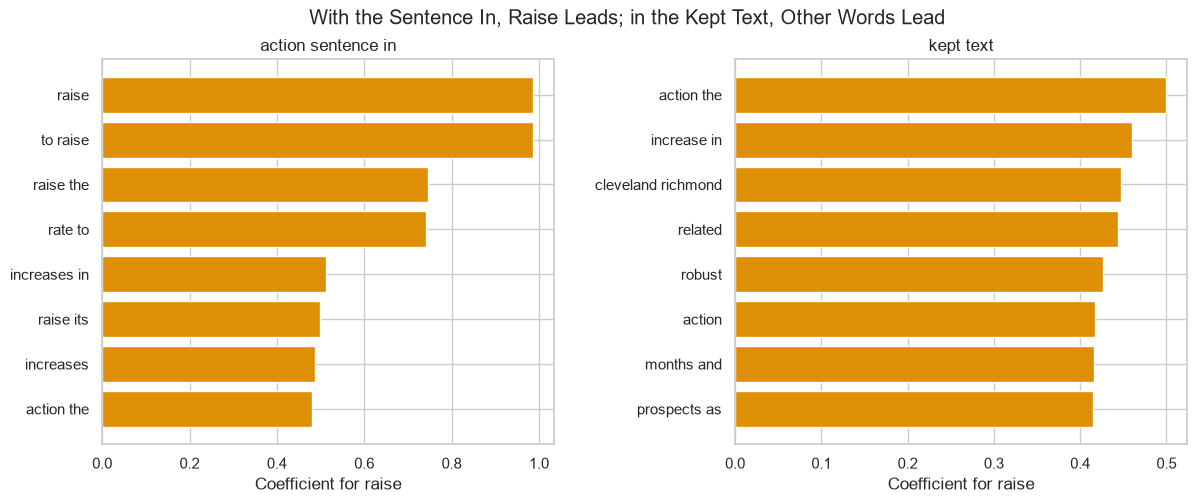

In [31]:
# source text: quoted as published
# the eight largest coefficients for raise in each run's last fold, ties broken by term (Day 2's np.lexsort)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"wspace": 0.4})
for ax, (name, model) in zip(axes, [("action sentence in", in_last), ("kept text", kept_last)]):
    terms, coef = model[0].get_feature_names_out(), model[-1].coef_[0]
    top = np.lexsort((terms, -coef))[:8]
    print(name, [(term, round(float(value), 4)) for term, value in zip(terms[top], coef[top])])
    ax.barh(terms[top][::-1], coef[top][::-1], color="C1")
    ax.set(xlabel="Coefficient for raise", title=name)
fig.suptitle("With the Sentence In, Raise Leads; in the Kept Text, Other Words Lead")
plt.show()

With the sentence in, "raise" and "to raise" lead: the model leans on the label's own words.

In the kept text "cleveland richmond" and "related" come from the discount rate sentences, which name the Reserve Banks whose requests they report.

A coefficient is what this fitted model leans on in this file, never a reason.

## The Related Action

In [32]:
# source text: quoted as published
# 2000-02-02's second sentence, then the kept texts that hold "related action" and "discount rate", by label and year
print(sentences(first_statement["policy"])[1])
statement_source(first_statement)
print(scheduled.loc[scheduled["kept"].str.contains("related action"), "label"].value_counts().to_dict())
discount = scheduled["kept"].str.contains("discount rate")
print(discount.sum(), "kept texts hold a discount rate sentence, from", scheduled["year"][discount].min(), "to", scheduled["year"][discount].max())

In a related action, the Board of Governors approved a 25 basis point increase in the discount rate to 5-1/4 percent.
Source: FOMC post-meeting statement of 2000-02-02, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/boarddocs/press/general/2000/20000202/
{'raise': 20, 'other': 18}
39 kept texts hold a discount rate sentence, from 2000 to 2008


"related action" sits in 38 kept texts, 20 of them stating a raise.

39 kept texts hold a discount rate sentence, all from 2000 to 2008: the action may still sit in another sentence.

**Predict 4**

Q. Remove the discount rate sentences from the kept text too, and run the loop again. Of the 173 assigned labels, how many change? Write down a number.

## The Discount Rate Sentences Removed Too

In [33]:
# the kept text without its discount rate sentences, the same loop, and the labels that change
scheduled["kept_no_discount"] = [" ".join(s for s in sentences(text) if "discount rate" not in s) for text in scheduled["kept"]]
no_discount, no_discount_last = walk_forward("kept_no_discount", "label")
print(f"macro F1 {f1_score(no_discount['label'], no_discount['assigned'], average='macro'):.4f} |",
      "assigned labels that change:", (no_discount["assigned"] != results["assigned"]).sum(), "of", len(results))
terms, coef = no_discount_last[0].get_feature_names_out(), no_discount_last[-1].coef_[0]
print("largest for raise in the last fold:", terms[np.lexsort((terms, -coef))[:3]].tolist())

macro F1 0.6510 | assigned labels that change: 0 of 173
largest for raise in the last fold: ['supply', 'imbalances', 'action the']


Macro F1 stays 0.6510, and the last fold now leans on "supply", "imbalances" and "action the".

Every discount rate sentence sits in 2000 to 2008, so only the four folds scoring 2005 to 2008 score a statement that holds one.

**A suspected leak is tested by removing it and running again; this one moved no assigned label.**

# Model Performance Evaluation

## Two Runs Against the Majority

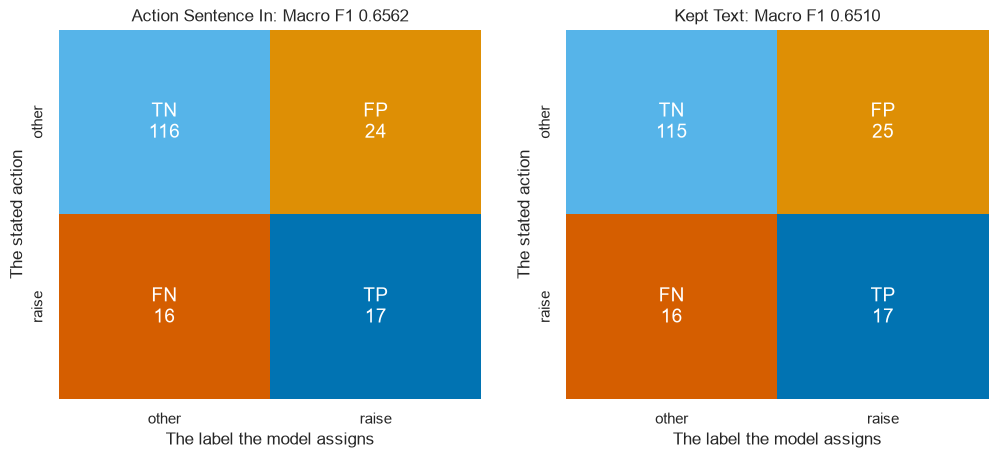

In [34]:
# the two runs against the stated action, in Course 4's Day 7 colours
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, run) in zip(axes, [("Action Sentence In", in_results), ("Kept Text", results)]):
    tn, fp, fn, tp = confusion_matrix(run["label"], run["assigned"], labels=["other", "raise"]).ravel()
    labels = [[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, annot_kws={"size": 14},
                xticklabels=["other", "raise"], yticklabels=["other", "raise"], ax=ax)
    ax.set(xlabel="The label the model assigns", ylabel="The stated action",
           title=f"{name}: Macro F1 {f1_score(run['label'], run['assigned'], average='macro'):.4f}")
plt.show()

Both runs find 17 of the 33 raises and miss 16.

They differ by one statement: the kept text assigns raise to 25 statements that state no raise, against 24.

**Predict 5**

Q. Sketch the classifier's score for raise for each of the 173 statements against its date, 2005 to 2026. Is it smooth, noisy, or something else?

## The Score by Date

A **spiral timeline** puts each statement at its day of the year as an angle, one turn a year, 2005 near the centre and 2026 at the edge.
Polar axes are Course 5's Day 3.

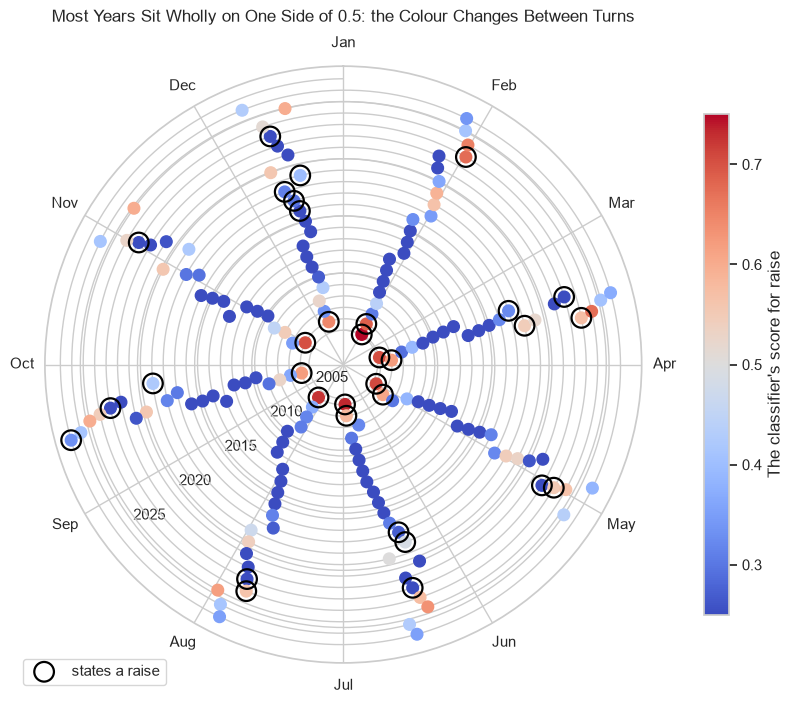

In [35]:
# angle: the day of the year (.dt.dayofyear), January at the top and clockwise; radius: one turn a year, 2005 starting at 3
when = pd.to_datetime(results["date"])
turn = (when.dt.dayofyear - 1) / 365
angle, radius = 2 * np.pi * turn, results["year"] - 2002 + turn
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.plot(2 * np.pi * np.linspace(0, 22, 4000), np.linspace(3, 25, 4000), color="0.8", lw=1)
# a score above 0.5 is assigned raise: red above the middle of the scale, blue below; stated raises ringed in black
dots = ax.scatter(angle, radius, c=results["score"], cmap="coolwarm", vmin=0.25, vmax=0.75, s=70, zorder=3)
raised = results["label"] == "raise"
ax.scatter(angle[raised], radius[raised], s=200, facecolors="none", edgecolors="black", linewidths=1.6, zorder=4, label="states a raise")
ax.set_xticks(2 * np.pi * np.arange(12) / 12, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks([3, 8, 13, 18, 23], ["2005", "2010", "2015", "2020", "2025"])
ax.set_rlabel_position(233)  # the year labels sit in late August, where no meeting falls
ax.legend(loc="lower left", bbox_to_anchor=(-0.05, -0.05))
plt.colorbar(dots, ax=ax, shrink=0.65, pad=0.08, label="The classifier's score for raise")
ax.set_title("Most Years Sit Wholly on One Side of 0.5: the Colour Changes Between Turns", pad=32)
plt.show()

### Interpretation of the Spiral

The **between-year share** of the score's variance is each year's mean less the overall mean, squared and summed, over the total of each score less the overall mean, squared (Course 4's `groupby().transform("mean")`).

In [36]:
# how much of the score's variance sits between years, and the years whose statements all get one assigned label
year_mean = results.groupby("year")["score"].transform("mean")
share = ((year_mean - results["score"].mean()) ** 2).sum() / ((results["score"] - results["score"].mean()) ** 2).sum()
per_year_raise = results.groupby("year")["assigned"].apply(lambda assigned: (assigned == "raise").mean())
print(f"between-year share {share:.4f} |", per_year_raise.isin([0, 1]).sum(), "of 22 years give every statement the same assigned label")
print("years with raise assigned to every statement:", per_year_raise.index[per_year_raise == 1].tolist())

between-year share 0.9259 | 19 of 22 years give every statement the same assigned label
years with raise assigned to every statement: [2005, 2019, 2023, 2024]


0.9259 of the score's variance sits between years: it jumps from year to year and barely moves inside one.

In 19 of 22 years every statement gets the same assigned label.

Every statement of 2019 and 2024 is assigned raise, and neither year states one (2019 states lowers).

## Year by Year

In [37]:
# stated and assigned raises in each scored year
raises_by_year = results.groupby("year").agg(statements=("label", "size"), stated=("label", lambda s: (s == "raise").sum()),
                                             assigned=("assigned", lambda s: (s == "raise").sum()))
print(raises_by_year.T.to_string())

year        2005  2006  2007  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
statements     8     8     8     8     8     8     8     8     8     8     8     8     8     8     8     7     8     8     8     8     8     6
stated         8     4     0     0     0     0     0     0     0     0     1     1     3     4     0     0     0     7     4     0     0     1
assigned       8     4     3     0     0     0     0     0     0     0     0     0     0     3     8     0     0     0     8     8     0     0


2022 states 7 raises and none is assigned; 2015 to 2017 state 5 and none is assigned.

2019 and 2024 account for 16 of the 25 raises assigned to statements that state no raise.

Statements of one year are worded alike, so resampling them as if independent would overstate how much the score was tested: the two periods below replace a bootstrap.

              classifier  majority label
2005 to 2014      0.9332          0.4595
2015 to 2026      0.4665          0.4364


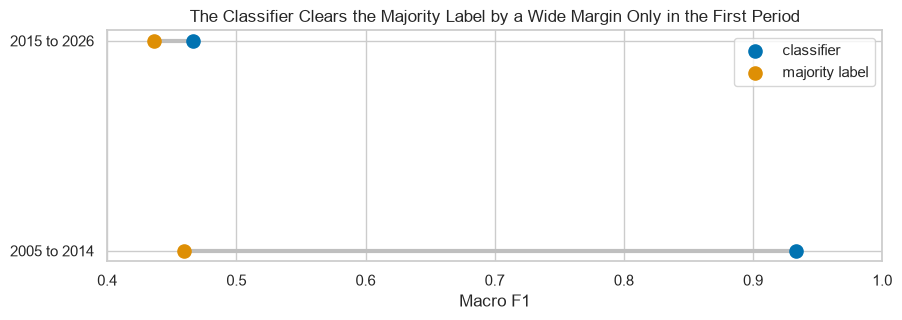

In [38]:
# macro F1 of the classifier and of the majority label in two periods, as dots joined by a line
periods = {}
for start, end in [(2005, 2014), (2015, 2026)]:
    part = results[results["year"].between(start, end)]
    periods[f"{start} to {end}"] = [f1_score(part["label"], part["assigned"], average="macro"), f1_score(part["label"], ["other"] * len(part), average="macro")]
periods = pd.DataFrame(periods, index=["classifier", "majority label"]).T
print(periods.round(4).to_string())
plt.figure(figsize=(10, 3))
plt.hlines(periods.index, periods["majority label"], periods["classifier"], color="0.75", lw=3)
plt.scatter(periods["classifier"], periods.index, s=90, label="classifier", zorder=3)
plt.scatter(periods["majority label"], periods.index, s=90, label="majority label", zorder=3)
plt.xlim(0.4, 1)
plt.legend()
plt.xlabel("Macro F1")
plt.title("The Classifier Clears the Majority Label by a Wide Margin Only in the First Period")
plt.show()

2005 to 2014: 0.9332 against 0.4595, and its 12 raises all sit in 2005 and 2006.

2015 to 2026: 0.4665 against 0.4364, over 21 raises.

**The classifier separates the wording of periods; most of the score it earns comes from 2005 and 2006.**

# Two Numbers Side by Side

## The Dictionary Score of Every Statement

In [39]:
# the course's word-list score on every kept text
scheduled["dictionary"] = [dictionary_score(text, FIRMING, EASING) for text in scheduled["kept"]]
print(scheduled["dictionary"].describe().round(4).to_dict())
print("exactly 0:", (scheduled["dictionary"] == 0).sum(), "| median by action:", scheduled.groupby("action")["dictionary"].median().round(4).to_dict())

{'count': 213.0, 'mean': -0.7452, 'std': 7.6753, 'min': -15.2672, '25%': -6.2598, '50%': -2.1142, '75%': 4.2918, 'max': 25.1572}
exactly 0: 39 | median by action: {'hold': -3.3784, 'lower': 0.0, 'raise': 3.9683}


The median kept text scores -2.1142, from -15.2672 to 25.1572, and 39 score exactly 0.

Statements that state a raise have the highest median, 3.9683; holds the lowest, -3.3784.

A **stem-and-leaf display** writes each score as digits: the stem is its whole part, the leaf its first decimal.

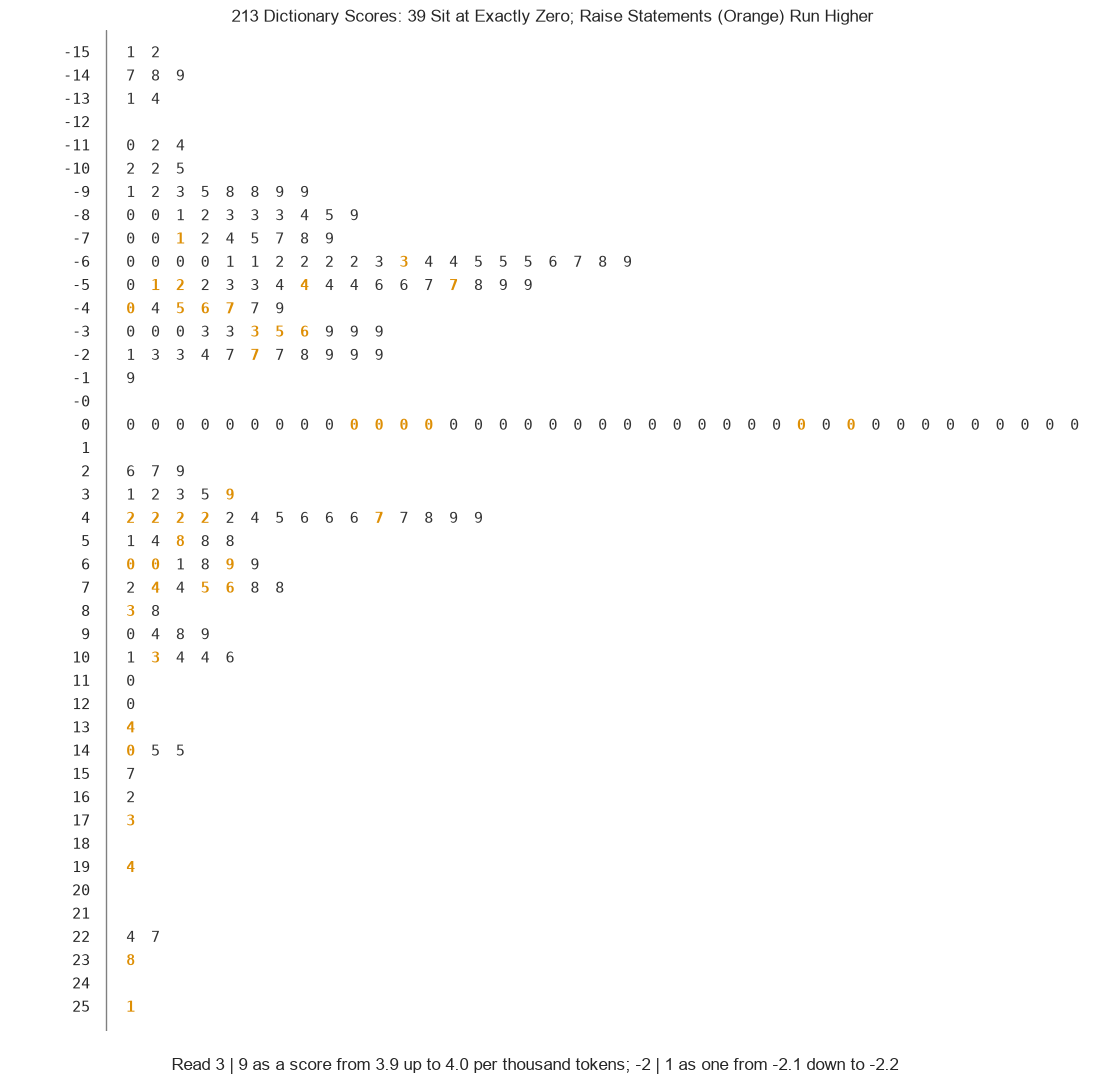

In [40]:
# stems: the whole part (np.trunc cuts the decimals toward zero, so -2.7 has stem -2, and -0.4 gets its own stem "-0");
# leaves: the first decimal; each row's leaves in order, the leaves of statements that state a raise in orange
scores = scheduled["dictionary"].to_numpy()
leaf_table = pd.DataFrame({"stem": np.where(scores < 0, "-", "") + np.abs(np.trunc(scores)).astype(int).astype(str),
                           "leaf": (np.abs(scores) * 10 % 10).astype(int), "raise": scheduled["label"] == "raise"}).sort_values("leaf", kind="stable")
rows = [f"-{k}" for k in range(15, -1, -1)] + [str(k) for k in range(26)]
fig, ax = plt.subplots(figsize=(14, 13))
for r, stem in enumerate(rows):
    ax.text(0, -r, stem, ha="right", va="center", family="monospace", fontsize=11)
    for j, (leaf, is_raise) in enumerate(leaf_table.loc[leaf_table["stem"] == stem, ["leaf", "raise"]].itertuples(index=False)):
        ax.text(0.9 + 0.62 * j, -r, leaf, va="center", family="monospace", fontsize=11, color="C1" if is_raise else "0.2", weight="bold" if is_raise else "normal")
ax.axvline(0.4, color="0.5", lw=1)
ax.set(xlim=(-2, 0.9 + 0.62 * leaf_table["stem"].value_counts().max()), ylim=(-len(rows), 1))
ax.set_axis_off()
ax.set_title("213 Dictionary Scores: 39 Sit at Exactly Zero; Raise Statements (Orange) Run Higher")
fig.text(0.5, 0.08, "Read 3 | 9 as a score from 3.9 up to 4.0 per thousand tokens; -2 | 1 as one from -2.1 down to -2.2", ha="center")
plt.show()

The 0 row is the widest, and the -0 and 1 rows are empty: a score that is not 0 sits at least 1.9 away from it.

Orange leaves run from -7 to 25, and the highest score, 25.1, states a raise.

## Your Turn: Leave One Word Out

Pick a word, and see each year's mean dictionary score with the full lists and without that word.

In [41]:
# each word's largest change to a yearly mean when it is left out of its list
full = scheduled.groupby("year")["dictionary"].mean()


def without(word):
    """Each year's mean dictionary score with one word left out of its list."""
    scores = [dictionary_score(text, [w for w in FIRMING if w != word], [w for w in EASING if w != word]) for text in scheduled["kept"]]
    return pd.Series(scores, index=scheduled["year"]).groupby(level=0).mean()


print({word: round(float((without(word) - full).abs().max()), 4) for word in FIRMING + EASING})

{'raise': 0.0, 'increase': 4.8881, 'tighten': 0.0, 'firming': 6.8667, 'elevated': 16.2376, 'lower': 4.9916, 'reduce': 1.2777, 'accommodation': 5.7127, 'accommodative': 8.3993, 'easing': 4.0291}


In [42]:
# the yearly mean with the full lists and without the chosen word
def draw_without(word="accommodative"):
    plt.plot(full.index, full, marker="o", label="the full lists")
    plt.plot(full.index, without(word), marker="o", label=f'without "{word}"')
    plt.axhline(0, color="0.5", lw=1)
    plt.legend()
    plt.xlabel("Year")
    plt.ylabel("Mean dictionary score (per thousand tokens)")
    plt.title(f'Leaving Out "{word}" Moves Each Year by Its Count in That Year')
    plt.show()


interact(draw_without, word=FIRMING + EASING);

interactive(children=(Dropdown(description='word', index=8, options=('raise', 'increase', 'tighten', 'firming'…

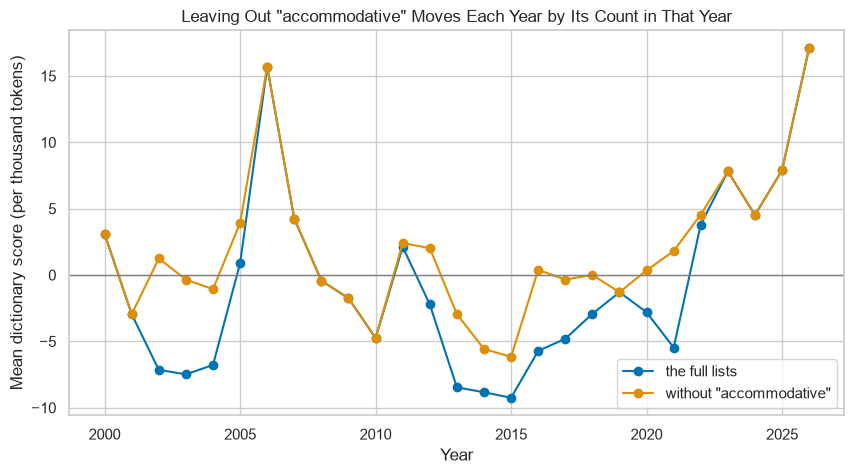

In [43]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
draw_without("accommodative")

Without "accommodative", every year whose kept texts hold it rises, 2002 to 2005, 2012 to 2018, 2020 and 2021 the most, by up to 8.3993.

Without "raise" or "tighten" nothing moves: neither is in a kept text.

"elevated" moves a year by up to 16.2376, the most of the ten.

## The Two Numbers Together

`Series.corr(method="spearman")` is a **rank correlation**: the correlation of the two numbers' ranks, so only their order counts.

In [44]:
# the 173 scored statements with both numbers, and the rank correlation between them
both = results.merge(scheduled[["date", "dictionary"]], on="date")
print(f"Spearman {both['score'].corr(both['dictionary'], method='spearman'):.4f} |",
      "dictionary median by stated label:", both.groupby("label")["dictionary"].median().round(4).to_dict())

Spearman 0.5552 | dictionary median by stated label: {'other': -2.3699, 'raise': 3.9683}


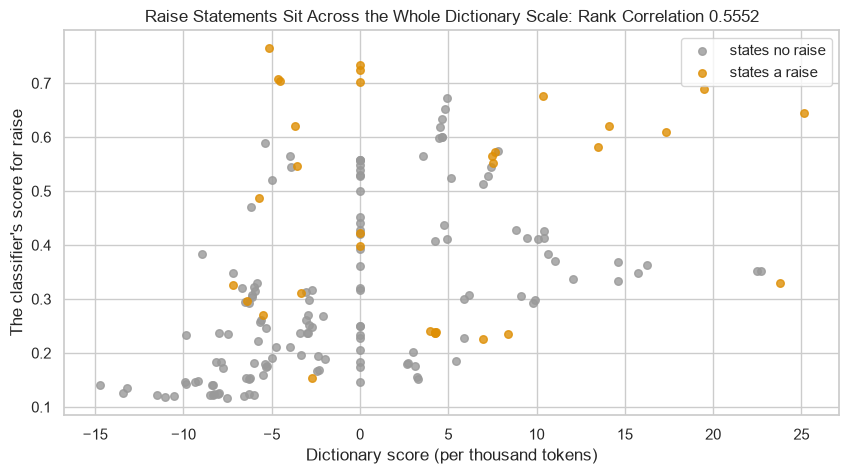

In [45]:
# the word-list score against the classifier's score, statements that state a raise in orange
for label, colour in [("other", "0.6"), ("raise", "C1")]:
    part = both[both["label"] == label]
    plt.scatter(part["dictionary"], part["score"], s=30, color=colour, alpha=0.8, label=f"states {'a raise' if label == 'raise' else 'no raise'}")
plt.legend()
plt.xlabel("Dictionary score (per thousand tokens)")
plt.ylabel("The classifier's score for raise")
plt.title(f"Raise Statements Sit Across the Whole Dictionary Scale: Rank Correlation {both['score'].corr(both['dictionary'], method='spearman'):.4f}")
plt.show()

One counts ten chosen words; the other weighs thousands of terms fitted on earlier years.

Their ranks agree only in part, and statements that state a raise sit across the whole dictionary scale.

**Both numbers describe wording already published, by date.**

# Insights and Conclusion

Six verbs read every scheduled statement's action, and agree with the stated rate on 221 of 221.

"raise" alone scores 0.9392 on the policy text, and is gone from the kept text.

Left in, the action sentence topped the coefficients and moved macro F1 by 0.0052.

The classifier scores 0.6510 against the majority's 0.4473, earned mostly in 2005 and 2006, and its score moves in year blocks.

Two of the five firming words count nothing in the kept text; "elevated" moves a year the most.

Neither number is a reading of policy.

**Take the label out, print the list, score each year from earlier years only; then say what each number counts.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Write two word lists and score a text per thousand tokens.
* Read the action a text states with a rule, and check the rule against a number the text states.
* Find the label's own sentence in a text, and take it out before any score.
* Score dated documents walk-forward by calendar year.
* Read a fitted model's coefficients, and test a suspected leak by removing it.
* Put two numbers side by side by date, and say what each one counts.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Without "elevated"**

Q. Take "elevated" off the firming list and score every kept text again. Store how many of the 213 scores change in `ex1_changed` and the new median in `ex1_median`.

In [47]:
# "elevated" off the firming list, every kept text scored again, then the scores that change and the new median
no_elevated = [dictionary_score(text, [w for w in FIRMING if w != "elevated"], EASING) for text in scheduled["kept"]]
ex1_changed = int((np.array(no_elevated) != scheduled["dictionary"]).sum())
ex1_median = float(np.median(no_elevated))
print(ex1_changed, "scores change | median", round(ex1_median, 4))

90 scores change | median -2.9674


In [48]:
check("Exercise 1 scores that change", ex1_changed, 90)
check("Exercise 1 median without elevated", ex1_median, -2.967359050445104)

Exercise 1 scores that change: correct
Exercise 1 median without elevated: correct


### Exercise 2

**Lower Against Other**

Q. Label each scheduled statement "lower" where its action is lower and "other" elsewhere, in a new column. Run `walk_forward` on the kept text with that column, and store the macro F1 in `ex2_macro_f1`.

In [49]:
# the new label column, the same loop on the kept text, and its macro F1
scheduled["lower"] = np.where(scheduled["action"] == "lower", "lower", "other")
lower_results, lower_last = walk_forward("kept", "lower")
ex2_macro_f1 = f1_score(lower_results["label"], lower_results["assigned"], average="macro")
print(f"macro F1 {ex2_macro_f1:.4f} |", (lower_results["label"] == "lower").sum(), "lowers scored")

macro F1 0.6503 | 17 lowers scored


In [50]:
check("Exercise 2 macro F1 for lower", ex2_macro_f1, 0.6502695417789758)

Exercise 2 macro F1 for lower: correct


### Exercise 3

**A Function by Year**

Q. Write `score_by_year(frame)`, which returns the count, mean and median of the `dictionary` column for each year. Store how many years of `score_by_year(scheduled)` have a median above zero in `ex3_years_above_zero`.

In [51]:
def score_by_year(frame):
    """The count, mean and median of the dictionary score for each year."""
    return frame.groupby("year")["dictionary"].agg(["count", "mean", "median"])


yearly = score_by_year(scheduled)
ex3_years_above_zero = int((yearly["median"] > 0).sum())
print(ex3_years_above_zero, "years above zero:", yearly.index[yearly["median"] > 0].tolist())

9 years above zero: [2000, 2006, 2007, 2011, 2022, 2023, 2024, 2025, 2026]


In [52]:
check("Exercise 3 years with a median above zero", ex3_years_above_zero, 9)

Exercise 3 years with a median above zero: correct


### Exercise 4: AI check

**A Score That Skips "Not"**

You asked an AI assistant for a dictionary score that leaves out every sentence holding "not".
This came back.
Before you run it, write down how many of the 213 scores you expect to differ from `dictionary_score`, then find the one bug.

In [53]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def score_outside_negations(text, firming, easing):
    """The dictionary score of the sentences without "not". On the text "Inflation remains elevated. The Committee
    did not raise the target range." (written for this lesson, from no statement) it counts 3 tokens."""
    counted = []
    for sentence in sentences(text):
        tokens = tokenize(sentence)
        if "Not" in tokens:
            continue
        counted = counted + tokens
    return (sum(t in firming for t in counted) - sum(t in easing for t in counted)) / len(counted) * 1000

In [54]:
# the docstring's promise, tested: its own text scored, beside 1 firming token in 3 tokens and 2 in all 11 tokens
promise = "Inflation remains elevated. The Committee did not raise the target range."
print("score:", round(score_outside_negations(promise, FIRMING, EASING), 4), "| 1 in 3 tokens:", round(1 / 3 * 1000, 4),
      "| 2 in 11 tokens:", round(2 / 11 * 1000, 4))

# the kept texts whose score differs from dictionary_score
print("scores that differ:", sum(score_outside_negations(t, FIRMING, EASING) != d for t, d in zip(scheduled["kept"], scheduled["dictionary"])))

score: 181.8182 | 1 in 3 tokens: 333.3333 | 2 in 11 tokens: 181.8182
scores that differ: 0


The docstring's own text scores 2 firming tokens in 11, not the 1 in 3 it promises: no sentence was skipped.

Q. Fix the one wrong line, score every kept text again, and store how many of the 213 scores differ from `dictionary_score` in `ex4_changed`.

In [55]:
# the fix: tokenize writes every token in lower case, so the test looks for "not", never "Not"
def score_outside_negations(text, firming, easing):
    """The dictionary score of the sentences without "not". On the text "Inflation remains elevated. The Committee
    did not raise the target range." (written for this lesson, from no statement) it counts 3 tokens."""
    counted = []
    for sentence in sentences(text):
        tokens = tokenize(sentence)
        if "not" in tokens:
            continue
        counted = counted + tokens
    return (sum(t in firming for t in counted) - sum(t in easing for t in counted)) / len(counted) * 1000


# the promise kept, then the kept texts whose score now differs
print("score:", round(score_outside_negations(promise, FIRMING, EASING), 4))
ex4_changed = sum(score_outside_negations(t, FIRMING, EASING) != d for t, d in zip(scheduled["kept"], scheduled["dictionary"]))
print("scores that differ:", ex4_changed)

score: 333.3333
scores that differ: 20


In [56]:
check("Exercise 4 scores that differ", ex4_changed, 20)

Exercise 4 scores that differ: correct


## Congratulations!

You read 213 real statements sentence by sentence and found the one sentence in each that states its action.
You checked that rule against the rate every statement states, took the label out of the text, and scored 22 years each with a model fitted only on earlier ones.
You caught a leak by its coefficients, tested another by removing it, and put two numbers side by side without reading either as policy.
Day 6 turns whole sentences into vectors with a pretrained model, and searches an indenture by meaning.

[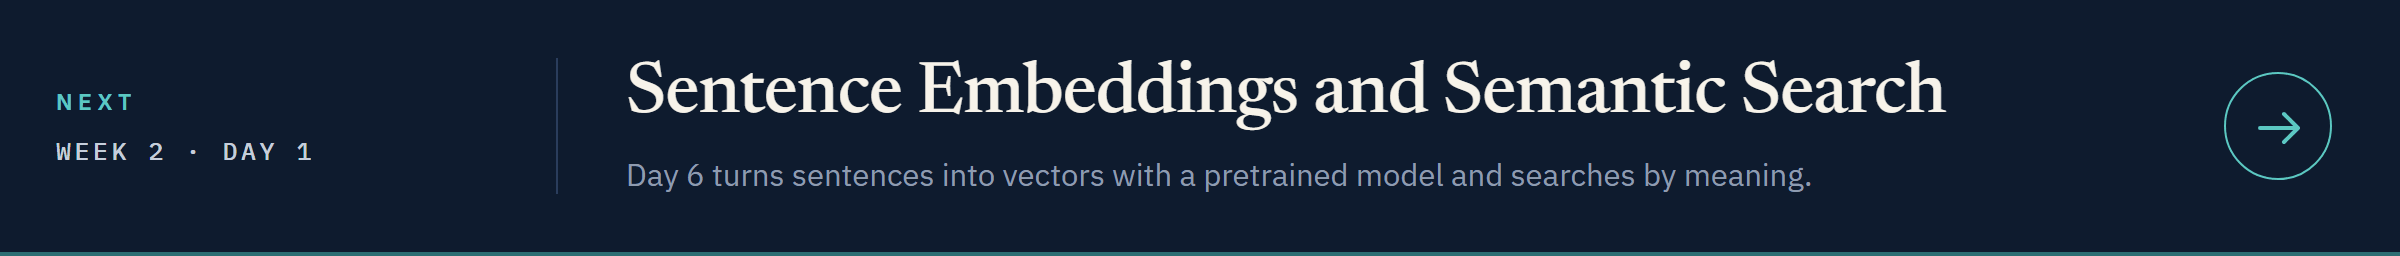](../../week2/day1/06_sentence_embeddings_and_semantic_search.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week2/day1/06_sentence_embeddings_and_semantic_search.ipynb)